# Phân tích giá nhà Ấn Độ — Ridge vs Random Forest

**Bài toán:** dự đoán **giá bán** của một căn nhà ở các thành phố Ấn Độ tại thời điểm giao dịch, dựa trên diện tích, số phòng, năm xây, vị trí, loại đường, nội thất, loại nhà, hồ bơi.

**Nguồn dữ liệu:** Kaggle — [raviiyadavv/house-price-predecition](https://www.kaggle.com/datasets/raviiyadavv/house-price-predecition), file `dataset_2.csv` (1.124 dòng × 9 cột).

> Lưu ý trung thực: file thật là `dataset_2.csv`, **không phải** bộ Housing.csv 545 dòng nổi tiếng mà mô tả Kaggle gợi tới. Mọi số trong notebook này đều chạy thật từ file đó.

**Cách chạy notebook này:**
- File `dataset_2.csv` phải nằm **cùng thư mục với notebook** (đã kèm sẵn). Cell dưới đây tự tìm file theo thư mục chứa notebook — nếu di chuyển notebook sang thư mục khác thì copy file CSV đi kèm, hoặc sửa biến `DATA_DIR` ở cell đầu tiên.
- Chạy lần lượt từ trên xuống dưới (Kernel → Restart & Run All). Môi trường: Python 3.12, scikit-learn 1.9.1, pandas 3.1.1, numpy 2.5.5, scipy 1.18.1, matplotlib.
- Mọi tham số tiền xử lý chỉ học từ **train**; chia ngẫu nhiên 80/20, `random_state=42` ở mọi chỗ.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Thư mục chứa notebook — file dataset_2.csv nằm cạnh notebook.
# Nếu di chuyển notebook, copy file CSV đi kèm hoặc sửa đường dẫn dưới đây.
DATA_DIR = Path.cwd()
CSV = DATA_DIR / "dataset_2.csv"
print("Đang đọc:", CSV)
print("File có tồn tại không:", CSV.exists())

df = pd.read_csv(CSV)
print("Kích thước:", df.shape, "(dòng × cột)")
print("Các cột:", list(df.columns))
display(df.head())
df.info()

Đang đọc: /home/hatch/workspace/your_files/notebooks/dataset_2.csv
File có tồn tại không: True
Kích thước: (1124, 9) (dòng × cột)
Các cột: ['Area_SqFt', 'Rooms', 'Build_Year', 'Location', 'Street_Type', 'Furnishing', 'Property_Type', 'Has_Pool', 'Price']


,Area_SqFt,Rooms,Build_Year,Location,Street_Type,Furnishing,Property_Type,Has_Pool,Price
0,2473.192784,4.0,1992,Jaipur,Residential Lane,Furnished,Apartment,No,568486.0
1,2353.472711,4.0,2006,Indore,Corner Plot,Unfurnished,Apartment,Yes,577214.0
2,2212.222005,3.0,2012,Jaipur,Highway Facing,Semi-Furnished,Duplex,No,581300.0
3,2823.886596,6.0,1993,Lucknow,Main Road,Unfurnished,Villa,Yes,794614.0
4,1869.648721,5.0,2012,Jaipur,Corner Plot,Semi-Furnished,Apartment,No,493086.0


<class 'pandas.DataFrame'>
RangeIndex: 1124 entries, 0 to 1123
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Area_SqFt      1091 non-null   float64
 1   Rooms          1091 non-null   float64
 2   Build_Year     1124 non-null   int64  
 3   Location       1124 non-null   str    
 4   Street_Type    1124 non-null   str    
 5   Furnishing     1091 non-null   str    
 6   Property_Type  1124 non-null   str    
 7   Has_Pool       1124 non-null   str    
 8   Price          1124 non-null   float64
dtypes: float64(3), int64(1), str(5)
memory usage: 79.2 KB


## Bài toán chính

Đây là bài toán **định giá** (hedonic pricing), không phải dự báo tương lai — không có cột thời gian nên chia ngẫu nhiên 80/20 (train 899 dòng, test 225 dòng).

- **Target chính là log(Giá)** — giá lệch phải mạnh nên lấy log cho phân bố cân lại, kết quả cuối quy về đơn vị tiền gốc để đọc.
- **Mốc đánh giá:** test R² > 0,80 ở cả hai thang (log giá và giá thật).
- **Hai mô hình:** Ridge Regression và Random Forest Regression, cùng một pipeline tiền xử lý.

## 1. EDA — Dữ liệu thiếu

Thiếu 99 ô: 33 ô ở mỗi cột `Area_SqFt`, `Rooms`, `Furnishing` — 97 dòng dính thiếu, tức 8,6% số dòng. Không có dòng trùng lặp hoàn toàn.

Số ô thiếu theo cột:
Area_SqFt        33
Rooms            33
Build_Year        0
Location          0
Street_Type       0
Furnishing       33
Property_Type     0
Has_Pool          0
Price             0
dtype: int64

Số dòng dính thiếu: 97 / 1124 = 8.6%


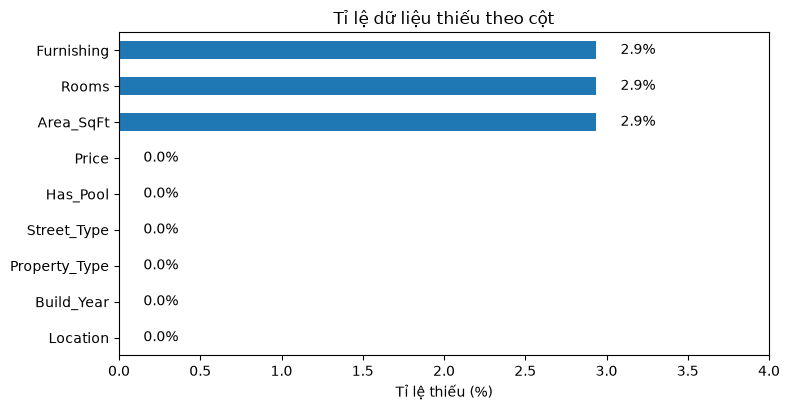

In [2]:
miss = (df.isna().mean() * 100).sort_values()
print("Số ô thiếu theo cột:")
print(df.isna().sum())
print(f"\nSố dòng dính thiếu: {df.isna().any(axis=1).sum()} / {len(df)} "
      f"= {df.isna().any(axis=1).mean()*100:.1f}%")

fig, ax = plt.subplots(figsize=(8, 4.2))
miss.plot.barh(ax=ax, color="#1f77b4")
ax.set_xlabel("Tỉ lệ thiếu (%)")
ax.set_title("Tỉ lệ dữ liệu thiếu theo cột")
for i, v in enumerate(miss.values):
    ax.text(v + 0.15, i, f"{v:.1f}%", va="center")
ax.set_xlim(0, 4)
plt.tight_layout()
plt.show()

**Đọc biểu đồ:** chỉ 3 cột dính thiếu, mỗi cột đúng 2,9%. Mức thiếu này nhẹ — xóa dòng sẽ mất gần 1/10 dữ liệu trên bộ chỉ 1.124 dòng, nên điền trung vị (số) / mốt (phân loại) là hợp lý hơn.

## 1. EDA — Phân bố giá: lệch phải nên phải lấy log

Giá trung bình 608.202, trung vị 602.541, min 248.640, max 2.071.402 — đuôi phải dài. Độ lệch (skew) 1,75, lấy log xong còn −0,11, gần như đối xứng.

Giá: trung bình 608,202 | trung vị 602,541 | min 248,640 | max 2,071,402
Skew giá thô: 1.75 | skew log(giá): -0.11
p99 giá: 972,420 (max gấp ~2 lần p99 — đuôi cực đoan)


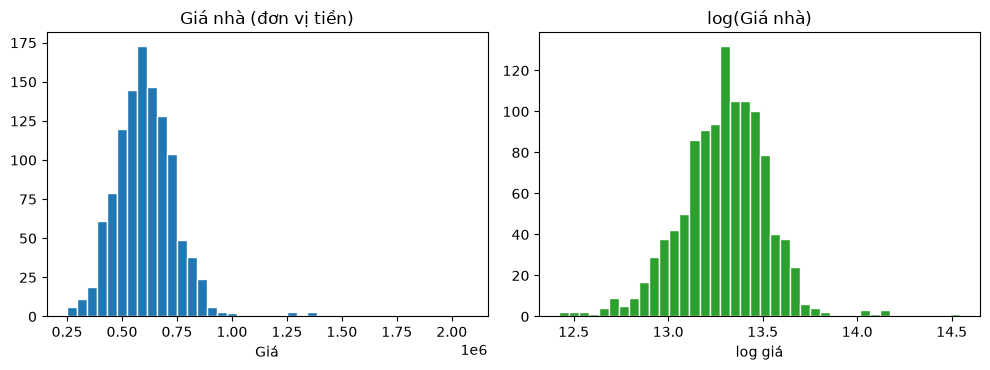

In [3]:
from scipy import stats as st

price = df["Price"]
print(f"Giá: trung bình {price.mean():,.0f} | trung vị {price.median():,.0f} | "
      f"min {price.min():,.0f} | max {price.max():,.0f}")
print(f"Skew giá thô: {price.skew():.2f} | skew log(giá): {np.log(price).skew():.2f}")
print(f"p99 giá: {price.quantile(0.99):,.0f} (max gấp ~2 lần p99 — đuôi cực đoan)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].hist(price, bins=40, color="#1f77b4", edgecolor="white")
axes[0].set_title("Giá nhà (đơn vị tiền)")
axes[0].set_xlabel("Giá")
axes[1].hist(np.log(price), bins=40, color="#2ca02c", edgecolor="white")
axes[1].set_title("log(Giá nhà)")
axes[1].set_xlabel("log giá")
plt.tight_layout()
plt.show()

**Đọc biểu đồ:** giá thô lệch phải rõ (bên trái dồn, bên phải kéo đuôi dài tới 2 triệu). Sau khi lấy log, phân bố gần như hình chuông — đó là lý do target của mọi mô hình trong notebook này là `log(Price)` chứ không phải giá thô. Kết quả cuối quy về đơn vị tiền gốc để đọc.

## 1. EDA — Diện tích quyết định giá

Diện tích trung bình 2.237 sqft, trung vị 2.202, min 700, max 10.267 (p99 chỉ 3.730) — lệch rất mạnh (skew 3,50, log xong còn −0,16). Tương quan với giá: diện tích **0,862** (mạnh nhất), số phòng 0,212, năm xây 0,112.

Diện tích: trung bình 2,237 | trung vị 2,202 | min 700 | max 10,267 | p99 3,730
Skew diện tích: 3.50 | skew log(diện tích): -0.16
Tương quan với Giá — diện tích: 0.862 | số phòng: 0.212 | năm xây: 0.112
Tương quan diện tích–số phòng: 0.028 (bất thường — xem giải thích dưới biểu đồ)


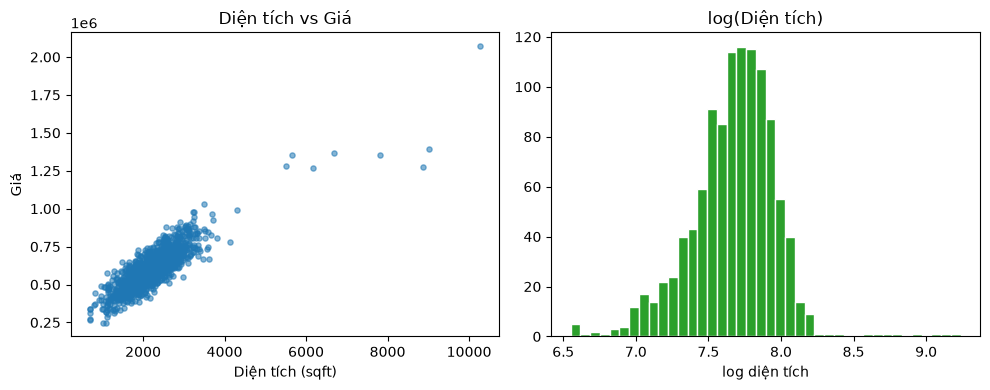

In [4]:
area = df["Area_SqFt"]
print(f"Diện tích: trung bình {area.mean():,.0f} | trung vị {area.median():,.0f} | "
      f"min {area.min():,.0f} | max {area.max():,.0f} | p99 {area.quantile(0.99):,.0f}")
print(f"Skew diện tích: {area.skew():.2f} | skew log(diện tích): {np.log(area).skew():.2f}")
print(f"Tương quan với Giá — diện tích: {df['Area_SqFt'].corr(df['Price']):.3f} | "
      f"số phòng: {df['Rooms'].corr(df['Price']):.3f} | năm xây: "
      f"{df['Build_Year'].corr(df['Price']):.3f}")
print(f"Tương quan diện tích–số phòng: {df['Area_SqFt'].corr(df['Rooms']):.3f} "
      "(bất thường — xem giải thích dưới biểu đồ)")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.0))
axes[0].scatter(df["Area_SqFt"], df["Price"], s=14, alpha=0.55, color="#1f77b4")
axes[0].set_xlabel("Diện tích (sqft)")
axes[0].set_ylabel("Giá")
axes[0].set_title("Diện tích vs Giá")
axes[1].hist(np.log(area), bins=40, color="#2ca02c", edgecolor="white")
axes[1].set_title("log(Diện tích)")
axes[1].set_xlabel("log diện tích")
plt.tight_layout()
plt.show()

**Đọc biểu đồ:** đám điểm chạy dốc lên theo diện tích — nhà càng rộng càng đắt, quan hệ gần như thẳng sau khi lấy log cả hai phía. Nhưng có một điểm bất thường cần ghi trung thực: **diện tích với số phòng gần như không tương quan (0,03)** — ngoài đời nhà to thường nhiều phòng. Dấu hiệu này gợi ý dữ liệu có thể được tổng hợp chứ không phải giao dịch thật 100%.

## 1. EDA — Ma trận tương quan

Nhìn nhanh xem biến nào đi cùng giá, biến nào trùng nhau (trùng nhau thì chỉ giữ một).

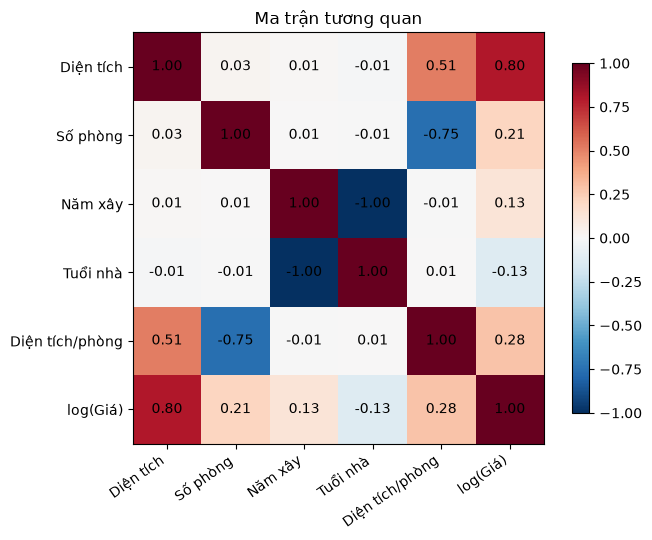

In [5]:
df["Age"] = 2025 - df["Build_Year"]
df["log_Area"] = np.log(df["Area_SqFt"])
df["Area_per_Room"] = df["Area_SqFt"] / df["Rooms"]
df["y"] = np.log(df["Price"])

corr = df[["Area_SqFt", "Rooms", "Build_Year", "Age", "Area_per_Room", "y"]].corr()
labels = ["Diện tích", "Số phòng", "Năm xây", "Tuổi nhà", "Diện tích/phòng", "log(Giá)"]
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=35, ha="right")
ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=10)
ax.set_title("Ma trận tương quan")
plt.colorbar(im, ax=ax, shrink=0.85)
plt.tight_layout()
plt.show()

**Đọc biểu đồ:** diện tích–log giá 0,86 là cặp mạnh nhất; số phòng–log giá chỉ 0,21. Tuổi nhà với năm xây tương quan −1,00 là hiển nhiên (tuổi = 2025 − năm xây) nên chỉ giữ một trong hai — notebook này giữ `Age`. Không có cặp feature nào trùng nhau tới mức phải bỏ (ngưỡng lo ngại thường là > 0,9).

## 1. EDA — Giá theo thành phố và loại nhà

Giá trung bình theo thành phố: Delhi 667.981; Gurugram 655.687; Noida 622.051; Lucknow 606.869; Indore 595.920; Jaipur 580.933; Kanpur 570.913; Prayagraj 567.968. Theo loại nhà: Villa 705.290; Duplex 628.432; Independent House 624.039; Apartment 573.034.

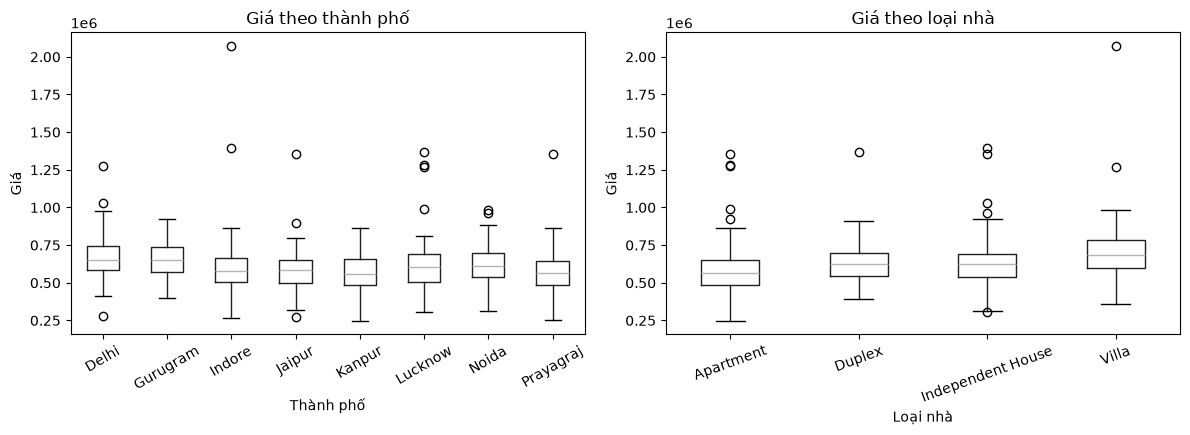

Giá trung bình theo thành phố:
Location
Delhi        667981.0
Gurugram     655687.0
Noida        622051.0
Lucknow      606869.0
Indore       595920.0
Jaipur       580933.0
Kanpur       570913.0
Prayagraj    567968.0
Name: Price, dtype: float64

Giá trung bình theo loại nhà:
Property_Type
Villa                705290.0
Duplex               628432.0
Independent House    624039.0
Apartment            573034.0
Name: Price, dtype: float64

Số dòng theo thành phố: Noida 156, Kanpur 147, Prayagraj 146, Delhi 144, Lucknow 138, Jaipur 133, Indore 133, Gurugram 127


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
df.boxplot(column="Price", by="Location", ax=axes[0], grid=False)
axes[0].set_title("Giá theo thành phố")
axes[0].set_xlabel("Thành phố")
axes[0].set_ylabel("Giá")
axes[0].tick_params(axis="x", rotation=30)
df.boxplot(column="Price", by="Property_Type", ax=axes[1], grid=False)
axes[1].set_title("Giá theo loại nhà")
axes[1].set_xlabel("Loại nhà")
axes[1].set_ylabel("Giá")
axes[1].tick_params(axis="x", rotation=20)
plt.suptitle("")
plt.tight_layout()
plt.show()

print("Giá trung bình theo thành phố:")
print(df.groupby("Location")["Price"].mean().sort_values(ascending=False).round(0))
print("\nGiá trung bình theo loại nhà:")
print(df.groupby("Property_Type")["Price"].mean().sort_values(ascending=False).round(0))
print("\nSố dòng theo thành phố: Noida 156, Kanpur 147, Prayagraj 146, Delhi 144, "
      "Lucknow 138, Jaipur 133, Indore 133, Gurugram 127")

**Đọc biểu đồ:** Delhi và Gurugram đắt nhất, Prayagraj rẻ nhất — chênh nhau khoảng 100.000, tức ~18% giá trung bình. Villa đắt nhất, Apartment rẻ nhất trong 4 loại nhà. Các hộp (box) chồng lấn nhau nhiều: thành phố và loại nhà chỉ giải thích một phần giá, diện tích mới là yếu tố chính.

## 1. EDA — Nội thất, hồ bơi và outlier

Theo nội thất: Furnished 631.178; Semi-Furnished 602.412; Unfurnished 584.549. Có hồ bơi 628.807 so với không có 600.801. Outlier (IQR): diện tích 18 dòng (1,6%), giá 15 dòng (1,3%). Không có cột nào suy ra từ giá — **không rò rỉ**.

In [7]:
print("Giá trung bình theo nội thất:")
print(df.groupby("Furnishing")["Price"].mean().round(0))
print("\nGiá trung bình theo hồ bơi:")
print(df.groupby("Has_Pool")["Price"].mean().round(0))
print("\nGiá mỗi sqft: trung bình "
      f"{(df['Price']/df['Area_SqFt']).mean():.1f} | min "
      f"{(df['Price']/df['Area_SqFt']).min():.1f} | max "
      f"{(df['Price']/df['Area_SqFt']).max():.1f}")

def iqr_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

print(f"\nOutlier (IQR) — diện tích: {iqr_outliers(df['Area_SqFt'])} dòng "
      f"({iqr_outliers(df['Area_SqFt'])/len(df)*100:.1f}%) | giá: "
      f"{iqr_outliers(df['Price'])} dòng ({iqr_outliers(df['Price'])/len(df)*100:.1f}%)")
print(f"Outlier diện tích lớn nhất: {df['Area_SqFt'].max():,.0f} sqft "
      f"(p99 chỉ {df['Area_SqFt'].quantile(0.99):,.0f})")

Giá trung bình theo nội thất:
Furnishing
Furnished         631178.0
Semi-Furnished    602412.0
Unfurnished       584549.0
Name: Price, dtype: float64

Giá trung bình theo hồ bơi:
Has_Pool
No     600801.0
Yes    628807.0
Name: Price, dtype: float64

Giá mỗi sqft: trung bình 281.1 | min 143.8 | max 537.8

Outlier (IQR) — diện tích: 18 dòng (1.6%) | giá: 15 dòng (1.3%)
Outlier diện tích lớn nhất: 10,267 sqft (p99 chỉ 3,730)


**Đọc kết quả:** nội thất đầy đủ và hồ bơi cộng thêm một ít giá (khoảng 30.000–45.000), nhưng đều nhỏ so với ảnh hưởng của diện tích. Outlier chỉ 1–2% số dòng nên không xóa dòng — winsorise ở bước tiền xử lý là đủ. Không có cột rò rỉ: không tỉ lệ hay giá trị nào được tính từ giá.

## 2. Tiền xử lý — 8 bước, mỗi bước có lý do

1. **Target `log(Price)`:** giá lệch phải mạnh (skew 1,75) nên log kéo đuôi về; kết quả cuối quy về đơn vị tiền gốc để đọc.
2. **`log(Area_SqFt)`:** diện tích lệch rất mạnh (skew 3,50, max 10.267 so với p99 3.730) nên log trước khi đưa vào mô hình; quan hệ diện tích–giá gần tuyến tính hơn ở thang log.
3. **Feature mới, không rò rỉ:** `Age = 2025 − Build_Year` (tuổi nhà dễ đọc hơn năm xây); `Area_per_Room = Area / Rooms` (diện tích mỗi phòng — nhà rộng nhưng nhiều phòng thì mỗi phòng vẫn chật, nên cần cả hai số).
4. **Median/mode impute học từ TRAIN:** 33 ô thiếu ở mỗi cột Area/Rooms/Furnishing (8,6% số dòng) — xóa dòng sẽ mất gần 1/10 dữ liệu trên bộ chỉ 1.124 dòng nên điền trung vị/mốt là hợp lý hơn.
5. **Winsorise 1%/99% theo train:** chặn đuôi cực đoan (Area max 10.267, Price max 2.071.402) thay vì xóa dòng.
6. **OneHot** cho Location, Street_Type, Furnishing, Property_Type; Has_Pool nhị phân.
7. **StandardScaler cho Ridge** (Ridge phạt hệ số nên cần cùng thang đo); Random Forest không cần scaler.
8. **Chia ngẫu nhiên 80/20, `random_state=42`:** train 899 / test 225. Mọi tham số tiền xử lý chỉ học từ TRAIN.

In [8]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUM = ["log_Area", "Rooms", "Age", "Area_per_Room"]
CAT = ["Location", "Street_Type", "Furnishing", "Property_Type", "Has_Pool"]
FEATS = NUM + CAT

X = df[FEATS]
y = df["y"]          # log(Price)
y_raw = df["Price"]  # giá gốc, chỉ dùng để tính metric thang tiền thật

X_tr, X_te, y_tr, y_te, yraw_tr, yraw_te = train_test_split(
    X, y, y_raw, test_size=0.2, random_state=42)
print(f"train {len(X_tr)} dòng | test {len(X_te)} dòng | features: {FEATS}")

# Ngưỡng winsorise 1%/99% — CHỈ học từ train
lo = X_tr[NUM].quantile(0.01).to_numpy()
hi = X_tr[NUM].quantile(0.99).to_numpy()
print("Ngưỡng winsorise (train 1%/99%) cho log_Area:",
      np.round([lo[0], hi[0]], 3))


class Winsoriser(BaseEstimator, TransformerMixin):
    """Chặn mỗi cột số về khoảng 1%/99% của train."""
    def fit(self, X, y=None):
        self.n_features_in_ = np.asarray(X).shape[1]
        return self
    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()
        return np.clip(X, lo, hi)


def prep(scaler):
    num_pipe = (make_pipeline(SimpleImputer(strategy="median"), Winsoriser(), scaler)
                if scaler else
                make_pipeline(SimpleImputer(strategy="median"), Winsoriser()))
    cat_pipe = make_pipeline(SimpleImputer(strategy="most_frequent"),
                             OneHotEncoder(handle_unknown="ignore"))
    return ColumnTransformer([("num", num_pipe, NUM), ("cat", cat_pipe, CAT)])

train 899 dòng | test 225 dòng | features: ['log_Area', 'Rooms', 'Age', 'Area_per_Room', 'Location', 'Street_Type', 'Furnishing', 'Property_Type', 'Has_Pool']
Ngưỡng winsorise (train 1%/99%) cho log_Area: [6.9   8.229]


**Cell trên đã làm gì:** chia train/test trước, rồi mới học ngưỡng winsorise từ train — thứ tự này quan trọng, vì học tham số tiền xử lý trên toàn bộ dữ liệu (kể cả test) là rò rỉ. `Winsoriser` chỉ chặn đuôi, không xóa dòng nào.

## 3. Lý thuyết ngắn — Ridge vs Random Forest

**Ridge Regression:** hồi quy tuyến tính + phạt L2 — phạt này kéo các hệ số nhỏ lại, chống overfitting và ổn định khi các biến tương quan nhau. Điểm mạnh: đọc được hệ số từng biến (mỗi m² thêm bao nhiêu, Villa cộng bao nhiêu so với Apartment). Điểm yếu: chỉ bắt được quan hệ thẳng (sau biến đổi log) — gặp quan hệ cong hay tương tác phức tạp thì đuối. Thắng khi quan hệ gần tuyến tính sau log — đúng trường hợp bộ này vì diện tích chi phối.

**Random Forest Regression:** trung bình 500 cây quyết định, mỗi cây học trên mẫu bootstrap và chỉ nhìn một tập con feature khi chia nhánh. Điểm mạnh: bắt được tương tác phi tuyến mà không cần khai báo trước. Điểm yếu: khó giải thích từng hệ số, dễ học vẹt train, không ngoại suy ngoài khoảng giá train.

**Khác biệt chính:** khi một feature tuyến tính áp đảo (diện tích corr 0,86 với giá) thì Ridge thắng; khi giá chạy theo vị trí phi tuyến (Melbourne, King County) thì Random Forest thắng.

## 4. Train và đánh giá — cả hai thang R²

Ridge: `RidgeCV` với lưới alpha [0,1; 1; 10; 100; 1000], chọn bằng CV 5-fold → α = 1,0. Random Forest: 500 cây, `min_samples_leaf=2`, `random_state=42`.

In [9]:
import time


def metrics(name, y_true_log, pred_log, y_true_raw, secs=None):
    usd_pred = np.exp(pred_log)
    m = {
        "R2_log": round(float(r2_score(y_true_log, pred_log)), 4),
        "R2_raw": round(float(r2_score(y_true_raw, usd_pred)), 4),
        "MAE_log": round(float(mean_absolute_error(y_true_log, pred_log)), 4),
        "MAE_raw": round(float(mean_absolute_error(y_true_raw, usd_pred)), 1),
        "RMSE_raw": round(float(mean_squared_error(y_true_raw, usd_pred) ** 0.5), 1),
        "MedAPE_pct": round(float(np.median(np.abs(usd_pred / y_true_raw - 1)) * 100), 2),
    }
    if secs is not None:
        m["train_sec"] = round(secs, 1)
    print(name, m)
    return m


results = {}

# Baseline: đoán trung bình train cho mọi nhà
pred_mean = np.full(len(X_te), y_tr.mean())
results["Mean baseline"] = metrics("Mean baseline", y_te, pred_mean, yraw_te)

# Ridge
t = time.time()
ridge = make_pipeline(prep(StandardScaler()),
                      RidgeCV(alphas=[0.1, 1, 10, 100, 1000], cv=5))
ridge.fit(X_tr, y_tr)
alpha = ridge[-1].alpha_
pred_ridge = ridge.predict(X_te)
results["Ridge"] = metrics("Ridge", y_te, pred_ridge, yraw_te, time.time() - t)
results["Ridge"]["alpha"] = float(alpha)
results["Ridge"]["R2_train_log"] = round(float(r2_score(y_tr, ridge.predict(X_tr))), 4)
kf = KFold(5, shuffle=True, random_state=42)
cv_ridge = cross_val_score(ridge, X, y, cv=kf, scoring="r2")
results["Ridge"]["CV_R2_mean"] = round(float(cv_ridge.mean()), 4)
results["Ridge"]["CV_R2_std"] = round(float(cv_ridge.std()), 4)
print("Ridge alpha:", alpha, "| CV R2 từng fold:", np.round(cv_ridge, 3))

# Random Forest
t = time.time()
rf = make_pipeline(prep(None),
                   RandomForestRegressor(n_estimators=500, min_samples_leaf=2,
                                         n_jobs=-1, random_state=42))
rf.fit(X_tr, y_tr)
pred_rf = rf.predict(X_te)
results["RandomForest"] = metrics("RandomForest", y_te, pred_rf, yraw_te, time.time() - t)
results["RandomForest"]["R2_train_log"] = round(float(r2_score(y_tr, rf.predict(X_tr))), 4)
cv_rf = cross_val_score(rf, X, y, cv=kf, scoring="r2")
results["RandomForest"]["CV_R2_mean"] = round(float(cv_rf.mean()), 4)
results["RandomForest"]["CV_R2_std"] = round(float(cv_rf.std()), 4)
print("RF CV R2 từng fold:", np.round(cv_rf, 3))

# Ví dụ 1 dòng test (dòng đầu tiên của test)
print("\nVí dụ 1 dòng test — thực tế:",
      f"{yraw_te.iloc[0]:,.0f} | Ridge đoán {np.exp(pred_ridge[0]):,.0f} | "
      f"RF đoán {np.exp(pred_rf[0]):,.0f}")

summary = pd.DataFrame(results).T[
    ["R2_log", "R2_raw", "MAE_raw", "RMSE_raw", "MedAPE_pct",
     "R2_train_log", "CV_R2_mean", "CV_R2_std"]]
display(summary)

Mean baseline {'R2_log': -0.0022, 'R2_raw': -0.0258, 'MAE_log': 0.187, 'MAE_raw': 112495.0, 'RMSE_raw': 147233.2, 'MedAPE_pct': 15.32}


Ridge {'R2_log': 0.9427, 'R2_raw': 0.9126, 'MAE_log': 0.0413, 'MAE_raw': 25938.5, 'RMSE_raw': 42973.4, 'MedAPE_pct': 3.39, 'train_sec': 0.1}


Ridge alpha: 1.0 | CV R2 từng fold: [0.943 0.908 0.922 0.923 0.892]


RandomForest {'R2_log': 0.89, 'R2_raw': 0.9009, 'MAE_log': 0.0612, 'MAE_raw': 36072.7, 'RMSE_raw': 45759.2, 'MedAPE_pct': 5.22, 'train_sec': 1.8}


RF CV R2 từng fold: [0.891 0.844 0.842 0.845 0.814]

Ví dụ 1 dòng test — thực tế: 700,394 | Ridge đoán 684,585 | RF đoán 756,568


,R2_log,R2_raw,MAE_raw,RMSE_raw,MedAPE_pct,R2_train_log,CV_R2_mean,CV_R2_std
Mean baseline,-0.0022,-0.0258,112495.0,147233.2,15.32,NaN,NaN,NaN
Ridge,0.9427,0.9126,25938.5,42973.4,3.39,0.9148,0.9176,0.0169
RandomForest,0.8900,0.9009,36072.7,45759.2,5.22,0.9615,0.8474,0.0248


**Đọc bảng kết quả (test 225 dòng):**

| Mô hình | R² log giá | R² giá thật | MAE | Sai số % trung vị |
|---|---|---|---|---|
| Trung bình (baseline) | −0,0022 | −0,0258 | 112.495 | 15,32% |
| **Ridge (α = 1,0)** | **0,9427** | **0,9126** | **25.938** | **3,39%** |
| Random Forest | 0,8900 | 0,9009 | 36.073 | 5,22% |

Cả hai đều vượt mốc 0,80 trên cả hai thang; **Ridge thắng RF** — ngược với Melbourne và King County. Vì sau log thì quan hệ gần như tuyến tính, diện tích một mình đã giải thích phần lớn giá. Sai số trung vị 3,39% (Ridge) nghĩa là cứ 2 căn thì 1 căn đoán lệch dưới ~3,4% giá thật.

## 4. Dự báo so với thực tế

Đường chéo đứt nét là "đoán đúng tuyệt đối" — điểm càng sát đường thì càng đúng.

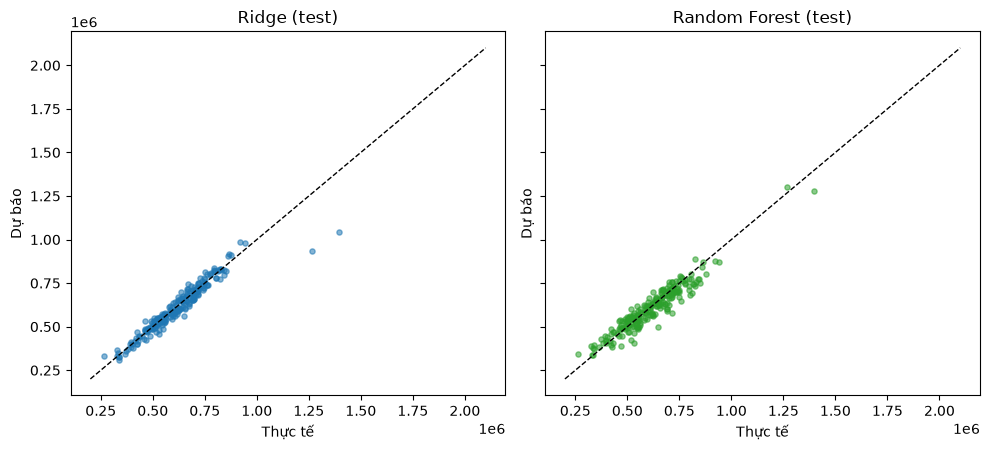

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for a, pred, name, c in [(axes[0], np.exp(pred_ridge), "Ridge", "#1f77b4"),
                         (axes[1], np.exp(pred_rf), "Random Forest", "#2ca02c")]:
    a.scatter(yraw_te, pred, s=14, alpha=0.55, color=c)
    lims = [200000, 2100000]
    a.plot(lims, lims, "k--", lw=1)
    a.set_title(f"{name} (test)")
    a.set_xlabel("Thực tế")
    a.set_ylabel("Dự báo")
plt.tight_layout()
plt.show()

**Đọc biểu đồ:** cả hai đám điểm đều ôm sát đường chéo — đúng với R² ~0,9. Random Forest lệch hơn ở hai đầu: nhà rẻ thì đoán cao quá, nhà đắt thì đoán thấp quá — cây không ngoại suy được ngoài khoảng giá train, còn Ridge (đường thẳng trên thang log) thì ngoại suy mượt hơn.

## 4. Phần dư — còn sai theo quy luật nào không?

Phần dư = thực tế − dự báo (thang log). Nếu mô hình đã học hết quy luật thì phần dư chỉ còn nhiễu ngẫu nhiên, trung bình ≈ 0 ở mọi mức giá.

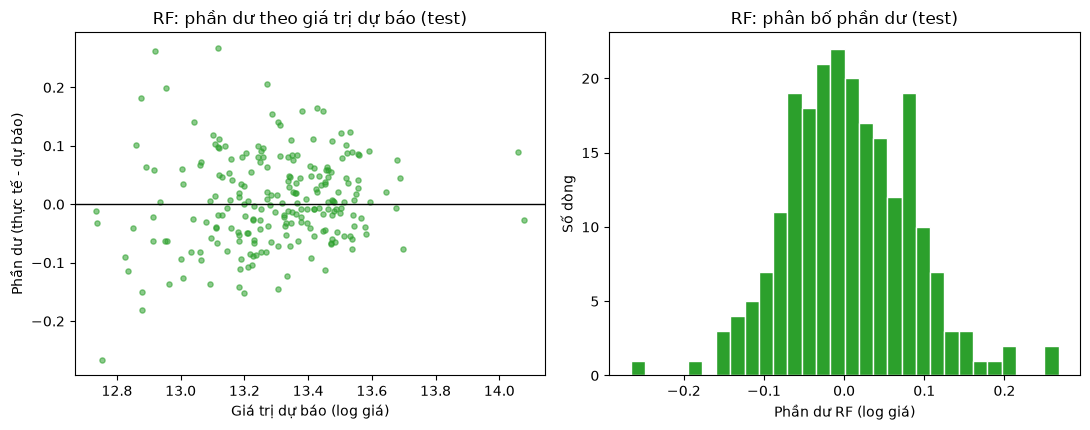

Phần dư RF theo thập phân vị dự báo (0 = nhà rẻ nhất, 9 = nhà đắt nhất):


,mean,std,count
decile,,,
0,-0.023,0.127,23
1,0.013,0.095,22
2,0.002,0.072,23
3,-0.025,0.070,22
4,0.025,0.089,23
5,0.007,0.056,22
6,0.011,0.060,22
7,0.017,0.067,23
8,0.021,0.059,22


Phần dư Ridge — trung bình 0.0031, độ lệch chuẩn 0.0565
Phần dư RF    — trung bình 0.0060, độ lệch chuẩn 0.0783


In [11]:
resid_rf = y_te.values - pred_rf
resid_ridge = y_te.values - pred_ridge

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].scatter(pred_rf, resid_rf, s=14, alpha=0.55, color="#2ca02c")
axes[0].axhline(0, color="black", lw=1)
axes[0].set_xlabel("Giá trị dự báo (log giá)")
axes[0].set_ylabel("Phần dư (thực tế - dự báo)")
axes[0].set_title("RF: phần dư theo giá trị dự báo (test)")
axes[1].hist(resid_rf, bins=30, color="#2ca02c", edgecolor="white")
axes[1].set_xlabel("Phần dư RF (log giá)")
axes[1].set_ylabel("Số dòng")
axes[1].set_title("RF: phân bố phần dư (test)")
plt.tight_layout()
plt.show()

dec = pd.qcut(pred_rf, 10, labels=False)
diag = pd.DataFrame({"decile": dec, "resid": resid_rf}).groupby("decile")["resid"].agg(["mean", "std", "count"])
print("Phần dư RF theo thập phân vị dự báo (0 = nhà rẻ nhất, 9 = nhà đắt nhất):")
display(diag.round(3))
print(f"Phần dư Ridge — trung bình {resid_ridge.mean():.4f}, độ lệch chuẩn {resid_ridge.std():.4f}")
print(f"Phần dư RF    — trung bình {resid_rf.mean():.4f}, độ lệch chuẩn {resid_rf.std():.4f}")

**Đọc biểu đồ và bảng:** phần dư RF trung bình −0,025 đến +0,025 ở mọi decile — gần 0 khắp nơi, tức mô hình không thiên lệch hệ thống theo mức giá. Độ lệch chuẩn 0,056–0,127, lớn nhất ở decile thấp nhất — nhà rẻ khó đoán hơn một chút. Histogram phần dư gần đối xứng quanh 0.

## 4. Q-Q plot — phần dư có gần phân phối chuẩn không?

Q-Q plot so phần dư chuẩn hoá với phân phối chuẩn lý thuyết: điểm nằm trên đường chéo thì phần dư gần chuẩn. Chuẩn hay không thì không bắt buộc với Ridge/RF (không như hồi quy suy luận), nhưng phần dư lệch chuẩn mạnh thường báo hiệu còn sót quy luật chưa học hoặc outlier nặng.

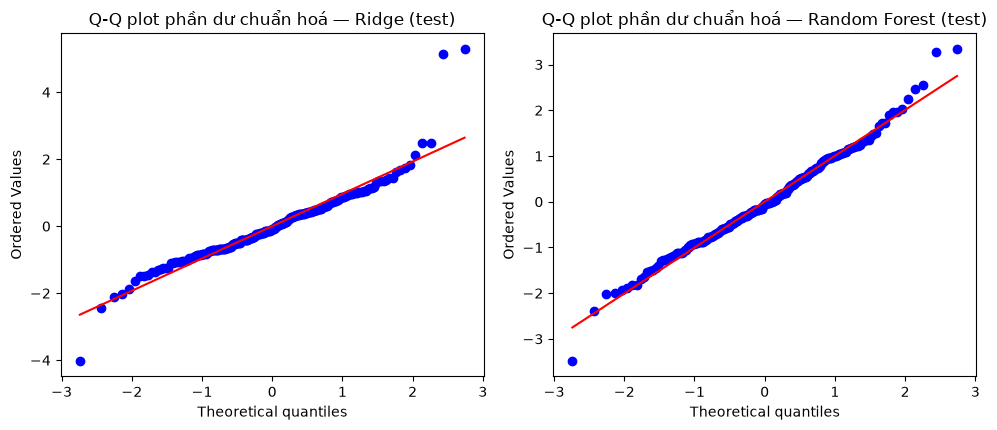

In [12]:
from scipy import stats as st

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, resid, name in [(axes[0], resid_ridge, "Ridge"),
                        (axes[1], resid_rf, "Random Forest")]:
    z = (resid - resid.mean()) / resid.std()
    st.probplot(z, dist="norm", plot=ax)
    ax.set_title(f"Q-Q plot phần dư chuẩn hoá — {name} (test)")
plt.tight_layout()
plt.show()

**Đọc Q-Q plot:** điểm bám đường chéo ở giữa, hơi cong ở hai đuôi — phần dư gần chuẩn nhưng đuôi hơi nặng (vài căn đoán lệch xa hơn phân phối chuẩn dự kiến). Đó là dấu vết của vài outlier giá/diện tích còn sót, không phải lỗi hệ thống — và cũng là lý do winsorise đã được dùng ở bước tiền xử lý.

## 4. Learning curve — thêm dữ liệu thì có khá hơn không?

Đường cong học vẽ R² train và R² kiểm chứng chéo theo cỡ mẫu train tăng dần. Hai đường hội tụ và cách nhau ít thì mô hình ổn định; đường train cao mà đường CV thấp và không hội tụ thì đang học vẹt.

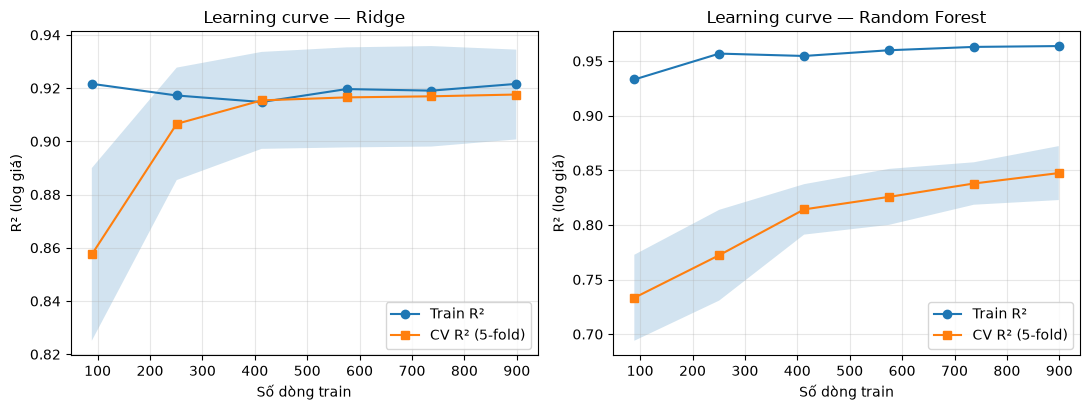

In [13]:
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, model, name in [(axes[0], ridge, "Ridge"),
                        (axes[1], rf, "Random Forest")]:
    sizes, tr, va = learning_curve(model, X, y, cv=kf,
                                   train_sizes=np.linspace(0.1, 1.0, 6),
                                   scoring="r2", n_jobs=-1)
    ax.plot(sizes, tr.mean(axis=1), "o-", label="Train R²")
    ax.plot(sizes, va.mean(axis=1), "s-", label="CV R² (5-fold)")
    ax.fill_between(sizes, va.mean(axis=1) - va.std(axis=1),
                    va.mean(axis=1) + va.std(axis=1), alpha=0.2)
    ax.set_title(f"Learning curve — {name}")
    ax.set_xlabel("Số dòng train")
    ax.set_ylabel("R² (log giá)")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Đọc learning curve:** Ridge — hai đường gần nhau và gần như phẳng từ sớm, tức thêm dữ liệu cũng không cải thiện bao nhiêu: mô hình đã chạm trần tuyến tính của nó. Random Forest — đường train cao hơn đường CV một khoảng rõ (dấu hiệu học vẹt nhẹ) nhưng khoảng hở thu hẹp dần khi thêm dữ liệu; thêm dữ liệu giúp RF một chút, nhưng không đổi được thứ hạng với Ridge ở bộ này.

## 4. Hệ số Ridge và permutation importance của Random Forest

Ridge đọc được hệ số từng biến (đã chuẩn hoá nên so sánh được với nhau). Random Forest thì đo bằng permutation importance: xáo một feature mà R² sập bao nhiêu thì feature đó quan trọng bấy nhiêu.

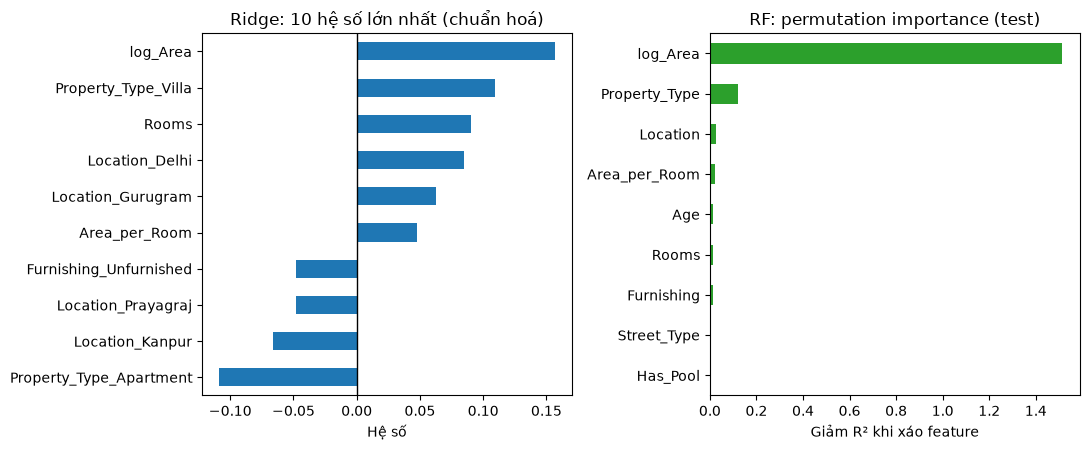

Top hệ số Ridge:
log_Area                   0.157
Property_Type_Villa        0.109
Property_Type_Apartment   -0.109
Rooms                      0.090
Location_Delhi             0.085
Location_Kanpur           -0.066
Location_Gurugram          0.063
Location_Prayagraj        -0.048
Furnishing_Unfurnished    -0.048
Area_per_Room              0.048
dtype: float64

RF permutation importance (test):
log_Area         1.5141
Property_Type    0.1203
Location         0.0258
Area_per_Room    0.0232
Age              0.0126
Rooms            0.0115
Furnishing       0.0113
Street_Type      0.0048
Has_Pool         0.0028
dtype: float64


In [14]:
from sklearn.inspection import permutation_importance

# Hệ số Ridge (sau OneHot)
ohe = ridge[0].named_transformers_["cat"][1]
cat_names = list(ohe.get_feature_names_out(CAT))
names = NUM + cat_names
coefs = dict(zip(names, np.round(ridge[-1].coef_, 3)))
top_coefs = pd.Series(coefs).reindex(
    pd.Series(coefs).abs().sort_values(ascending=False).index[:10])

perm = permutation_importance(rf, X_te, y_te, n_repeats=5, random_state=42, n_jobs=-1)
perm_imp = dict(zip(FEATS, np.round(perm.importances_mean, 4)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
top_coefs.sort_values().plot.barh(ax=axes[0], color="#1f77b4")
axes[0].axvline(0, color="black", lw=1)
axes[0].set_title("Ridge: 10 hệ số lớn nhất (chuẩn hoá)")
axes[0].set_xlabel("Hệ số")
pd.Series(perm_imp).sort_values().plot.barh(ax=axes[1], color="#2ca02c")
axes[1].set_title("RF: permutation importance (test)")
axes[1].set_xlabel("Giảm R² khi xáo feature")
plt.tight_layout()
plt.show()

print("Top hệ số Ridge:")
print(top_coefs)
print("\nRF permutation importance (test):")
print(pd.Series(perm_imp).sort_values(ascending=False))

**Đọc biểu đồ:** Ridge — `log_Area` +0,157 mạnh nhất; Villa +0,109 và Apartment −0,109 đối xứng nhau (Villa đắt hơn Apartment sau khi đã tính diện tích); Delhi +0,085, Kanpur −0,066. Random Forest — `log_Area` 1,5141 áp đảo (xáo nó là R² sập), tiếp theo là Property_Type 0,1203, còn lại đều nhỏ. Kết luận chung: **diện tích quyết định gần như mọi thứ; các yếu tố khác chỉ là điểm cộng/trừ nhỏ.**

## 5. Kiểm tra mô hình — học thật, học chưa tới, hay học vẹt?

- **Underfitting (học chưa tới):** học chưa đủ nên cả đề cũ (train) lẫn đề mới (test) đều sai.
- **Overfitting chính là học vẹt:** thuộc lòng cả nhiễu trong đề cũ — điểm học cao nhưng gặp dữ liệu mới thì tụt.
- **Cách kiểm tra:** so R² train với R² test + kiểm chứng 5-fold (CV). Chênh nhỏ + CV ổn định = không học vẹt; cả hai đều cao = không học chưa tới.

In [15]:
check = pd.DataFrame({
    "Ridge": [results["Ridge"]["R2_train_log"], results["Ridge"]["R2_log"],
              results["Ridge"]["CV_R2_mean"], results["Ridge"]["CV_R2_std"]],
    "RandomForest": [results["RandomForest"]["R2_train_log"],
                     results["RandomForest"]["R2_log"],
                     results["RandomForest"]["CV_R2_mean"],
                     results["RandomForest"]["CV_R2_std"]],
    "Mean baseline": [None, results["Mean baseline"]["R2_log"], None, None],
}, index=["R² lúc học (train)", "R² kiểm tra (test)", "Kiểm chứng 5-fold (CV)",
           "Độ lệch chuẩn CV"])
check["Khoảng hở train–test (Ridge)"] = [results["Ridge"]["R2_train_log"]
                                         - results["Ridge"]["R2_log"], None, None, None]
check["Khoảng hở train–test (RF)"] = [results["RandomForest"]["R2_train_log"]
                                      - results["RandomForest"]["R2_log"], None, None, None]
display(check)

,Ridge,RandomForest,Mean baseline,Khoảng hở train–test (Ridge),Khoảng hở train–test (RF)
R² lúc học (train),0.9148,0.9615,NaN,-0.0279,0.0715
R² kiểm tra (test),0.9427,0.8900,-0.0022,NaN,NaN
Kiểm chứng 5-fold (CV),0.9176,0.8474,NaN,NaN,NaN
Độ lệch chuẩn CV,0.0169,0.0248,NaN,NaN,NaN


**Kết luận kiểm tra — bằng số thật của lần chạy này:**

- **Ridge không học vẹt, không học chưa tới:** train 0,9148 với test 0,9427 — test còn *cao hơn* train (do lần chia test ngẫu nhiên hơi dễ hơn), CV 0,9176 ± 0,0169 trùng cả hai. R² 0,94 gấp xa baseline −0,0022 nên không thể gọi là học chưa tới.
- **Random Forest học vẹt nhẹ:** train 0,9615 với test 0,8900, hở 0,0715 — cây sâu nhớ được một phần train. Nhưng test vẫn cao (0,89) và CV 0,8474 ± 0,0248 ổn định nên overfitting nhẹ, không gây hại. Nó được kiềm bởi `min_samples_leaf=2` (lá phải có ít nhất 2 dòng mới được chia tiếp) và trung bình 500 cây.
- **Baseline đoán trung bình là ví dụ underfitting cực đoan:** R²_log −0,0022 — mô hình đoán cùng một số cho mọi nhà, không học được gì.

## 6. Kết luận

- **Cả hai mô hình đều vượt mốc R² > 0,80** trên cả hai thang đo; Ridge thắng Random Forest (0,9427 so với 0,8900 trên log giá) vì sau log thì quan hệ gần như tuyến tính và diện tích một mình đã giải thích phần lớn giá.
- **Ý nghĩa thực tiễn:** giá nhà chạy theo diện tích trước tiên; sau đó mới tới loại nhà (Villa đắt nhất, Apartment rẻ nhất), thành phố (Delhi, Gurugram đắt nhất), nội thất đầy đủ và hồ bơi cộng thêm một ít. Sai số trung vị chỉ 3,39% (Ridge).
- **Hạn chế:** mẫu nhỏ (1.124 dòng, test chỉ 225 dòng) nên ước lượng kém ổn định hơn các bộ lớn; diện tích với số phòng gần như không tương quan (0,03) — phi thực tế, gợi ý dữ liệu có thể được tổng hợp; không có biến vị trí chi tiết (tọa độ), không có thời gian giao dịch, không có biến kinh tế vĩ mô; Random Forest overfit nhẹ.

## 7. Thêm: vòng gộp tiền xử lý — gộp 3 có phải tốt nhất không?

Sau vòng chạy chính, đã thử thêm một vòng tối ưu tiền xử lý cho Ridge và Random Forest, so sánh bằng 5-fold CV trên train (test chỉ chạm 1 lần cho phương án thắng). Ba can thiệp thử gộp: tương tác (`log_Area×Rooms`, `log_Area×Age`) + KNN impute (k=5) + bậc hai `log_Area²`.

| Phương án (Ridge CV R²_log) | Giá trị |
|---|---|
| Gốc (tính chặt chẽ) | 0,9084 |
| Tương tác đơn | 0,9087 |
| KNN impute | 0,8988 |
| Bậc hai `log_Area²` | 0,9123 |
| Pair2: tương tác + bậc hai | **0,9124 — thắng** |
| **Gộp 3** | **0,9015 — thua cả gốc** |

**Kết quả: gộp 3 KHÔNG tốt nhất — nó thua cả pipeline gốc.** Thủ phạm là KNN impute, làm hại cả hai mô hình (Ridge −0,0096, RF −0,0153 CV): chỉ thiếu 8,6% số dòng nên điền trung vị đã đủ tốt; Area với Rooms gần như không tương quan (0,03) nên hàng xóm gần không mang thông tin gì về giá trị thiếu; và KNN điền ra số phòng lẻ (ví dụ 4,3 phòng) cho một biến rời rạc.

Phương án tốt nhất cho Ridge là **pair2 (tương tác + bậc hai): test R²_log 0,9444 / R²_raw 0,9179, MAE 25.379** — chỉ hơn gốc 0,0017, không đáng kể. Random Forest + tương tác test 0,8873, còn tệ hơn gốc 0,8900. **Tiền xử lý không phải nút thắt ở bộ này** — Ridge gốc đã 0,9427 nên dư địa gần như không còn.

Cell dưới đây minh hoạ pair2 (tương tác + bậc hai) — chạy lại đúng logic vòng gộp để đối chiếu số 0,9444.

In [16]:
# Minh hoạ pair2 (tương tác + log_Area^2) — logic vòng gộp, chạy nhanh trên train/test
from sklearn.preprocessing import OneHotEncoder as _OHE

raw_cols = ["Area_SqFt", "Rooms", "Build_Year", "Location", "Street_Type",
            "Furnishing", "Property_Type", "Has_Pool"]
X_raw = df[raw_cols]
Xr_tr, Xr_te, yr_tr, yr_te, yrawr_tr, yrawr_te = train_test_split(
    X_raw, y, y_raw, test_size=0.2, random_state=42)


def derive_pair2(Xdf, med=None, lo_q=None, hi_q=None, modes=None, fit=False):
    D = pd.DataFrame(index=Xdf.index)
    D["log_Area"] = np.log(Xdf["Area_SqFt"])
    D["Rooms"] = Xdf["Rooms"].astype(float)
    D["Age"] = 2025 - Xdf["Build_Year"]
    if fit:
        med = D.median()
        modes = {c: Xdf[c].mode(dropna=True)[0] for c in CAT}
    D = D.fillna(med)
    D["Area_per_Room"] = np.exp(D["log_Area"]) / D["Rooms"]
    if fit:
        lo_q, hi_q = D.quantile(0.01), D.quantile(0.99)
    D = D.clip(lower=lo_q, upper=hi_q, axis=1)
    D["inter_area_rooms"] = D["log_Area"] * D["Rooms"]
    D["inter_area_age"] = D["log_Area"] * D["Age"]
    D["log_area_sq"] = D["log_Area"] ** 2
    C = pd.DataFrame({c: Xdf[c].fillna(modes[c]).astype(str) for c in CAT},
                     index=Xdf.index)
    return D, C, med, lo_q, hi_q, modes


num2_tr, cat2_tr, med2, lo2, hi2, modes2 = derive_pair2(Xr_tr, fit=True)
num2_te, cat2_te, *_ = derive_pair2(Xr_te, med2, lo2, hi2, modes2)

enc = _OHE(handle_unknown="ignore", sparse_output=False)
cat2_tr_ohe = enc.fit_transform(cat2_tr)
cat2_te_ohe = enc.transform(cat2_te)
sc2 = StandardScaler()
X2_tr = np.hstack([sc2.fit_transform(num2_tr), cat2_tr_ohe])
X2_te = np.hstack([sc2.transform(num2_te), cat2_te_ohe])

ridge2 = RidgeCV(alphas=[0.1, 1, 10, 100, 1000], cv=5)
ridge2.fit(X2_tr, yr_tr)
pred2 = ridge2.predict(X2_te)
m2 = metrics("Ridge + pair2 (tương tác + bậc hai)", yr_te, pred2, yrawr_te)
print("alpha được chọn:", ridge2.alpha_)
print("Kỳ vọng theo vòng gộp: R2_log 0,9444 / R2_raw 0,9179 / MAE 25.379")

Ridge + pair2 (tương tác + bậc hai) {'R2_log': 0.9444, 'R2_raw': 0.9179, 'MAE_log': 0.0403, 'MAE_raw': 25379.2, 'RMSE_raw': 41663.5, 'MedAPE_pct': 3.16}
alpha được chọn: 0.1
Kỳ vọng theo vòng gộp: R2_log 0,9444 / R2_raw 0,9179 / MAE 25.379


**Đọc cell pair2:** nếu số in ra khớp kỳ vọng (R²_log ≈ 0,9444) thì minh hoạ đã tái hiện đúng vòng gộp. Chênh lệch +0,0017 so với pipeline gốc là quá nhỏ để kết luận — với mẫu chỉ 225 dòng test, đó là nhiễu. Bài học xuyên suốt: **tiền xử lý chỉ là nút thắt khi pipeline gốc còn thiếu thứ gì đó** (như ở Melbourne); khi pipeline gốc đã đủ thì gộp thêm chỉ thêm nhiễu.